# 06 Calibration and decision threshold
**Question 1:** are the model's scores real probabilities? **Question 2:** which score cut-off should raise an alert?

Rules followed here:
- Calibrators and the threshold are learned from **out-of-fold training scores** only, so the validation split stays an honest check.
- The test split is never loaded.
- Scores are never read as probabilities until they have been calibrated, and the cut-off is never 0.5 by default.

In [1]:
import json
import sys
import textwrap
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.pipeline import SEED, load_splits, split_xy  # noqa: E402

MODEL_PATH = ROOT / "models" / "best_model.joblib"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Set ONE of these from the Week 2 roadmap (for example TARGET_PRECISION = 0.30).
# Leave both as None to pick the threshold that maximises F1.
TARGET_PRECISION = None
TARGET_RECALL = None

## 1. Load the saved model and the validation split

In [2]:
model = joblib.load(MODEL_PATH)
train, val, _ = load_splits(str(ROOT / "data" / "clean" / "clean.parquet"))
x_tr, y_tr = split_xy(train)
x_val, y_val = split_xy(val)
y_arr = y_val.to_numpy()
val_raw = model.predict_proba(x_val)[:, 1]
rate = float(y_val.mean())
print(f"train rows {len(x_tr):,} | validation rows {len(x_val):,} | validation positives {int(y_arr.sum())}")
print(f"validation PR-AUC {average_precision_score(y_val, val_raw):.4f} (should match 0.2459)")
print(f"validation ROC-AUC {roc_auc_score(y_val, val_raw):.4f} (should match 0.793)")

train rows 17,500 | validation rows 3,750 | validation positives 147
validation PR-AUC 0.2459 (should match 0.2459)
validation ROC-AUC 0.7930 (should match 0.793)


## 2. Are the raw scores probabilities?
If they were, the average score would be close to the true anomaly rate.

In [3]:
print(f"true anomaly rate in validation  : {rate:.4f}")
print(f"mean raw score in validation     : {val_raw.mean():.4f}")
print(f"lowest raw score of a true anomaly: {val_raw[y_arr == 1].min():.3f}")
print(f"Brier score, always predict {rate:.3f}: {rate * (1 - rate):.4f}")
print(f"Brier score, raw model scores    : {brier_score_loss(y_val, val_raw):.4f}")

true anomaly rate in validation  : 0.0392
mean raw score in validation     : 0.3751
lowest raw score of a true anomaly: 0.299
Brier score, always predict 0.039: 0.0377
Brier score, raw model scores    : 0.1550


## 3. Fit calibrators on out-of-fold training scores
Each training row gets a score from a model that never saw it. Two calibrators are compared: Platt scaling (a logistic curve on the log-odds) and isotonic regression (a step function).

In [4]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_raw = cross_val_predict(clone(model), x_tr, y_tr, cv=folds, method="predict_proba")[:, 1]


def logit(p):
    """Log-odds of a probability, clipped away from 0 and 1."""
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(oof_raw).reshape(-1, 1), y_tr)
iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(oof_raw, y_tr)


def to_platt(p):
    """Apply the fitted Platt scaling to raw scores."""
    return platt.predict_proba(logit(p).reshape(-1, 1))[:, 1]


oof_platt = to_platt(oof_raw)
val_platt = to_platt(val_raw)
val_iso = iso.predict(val_raw)
print(f"out-of-fold PR-AUC on training rows: {average_precision_score(y_tr, oof_raw):.4f}")

out-of-fold PR-AUC on training rows: 0.2642


In [5]:
rows = []
for name, score in (("raw", val_raw), ("platt", val_platt), ("isotonic", val_iso)):
    rows.append(
        {
            "scores": name,
            "mean score": round(float(np.mean(score)), 4),
            "Brier": round(brier_score_loss(y_val, score), 4),
            "log loss": round(log_loss(y_val, np.clip(score, 1e-6, 1 - 1e-6)), 4),
            "PR-AUC": round(average_precision_score(y_val, score), 4),
            "ROC-AUC": round(roc_auc_score(y_val, score), 4),
        }
    )
calib_table = pd.DataFrame(rows).set_index("scores")
calib_table.to_csv(ROOT / "reports" / "calibration_table.csv")
print(f"true anomaly rate in validation: {rate:.4f} (Brier of a constant guess: {rate * (1 - rate):.4f})")
calib_table

true anomaly rate in validation: 0.0392 (Brier of a constant guess: 0.0377)


,mean score,Brier,log loss,PR-AUC,ROC-AUC
scores,,,,,
raw,0.3751,0.1550,0.4982,0.2459,0.7930
platt,0.0389,0.0332,0.1314,0.2459,0.7930
isotonic,0.0387,0.0330,0.1308,0.2358,0.8048


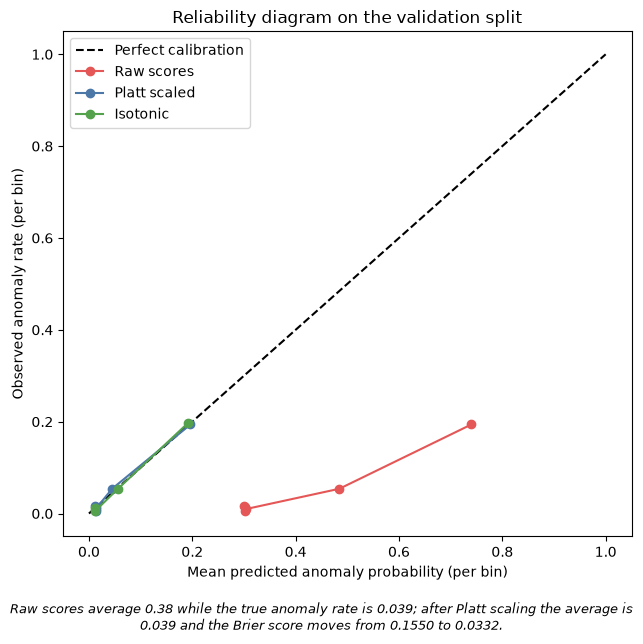

calibration_curve.png: Raw scores average 0.38 while the true anomaly rate is 0.039; after Platt scaling the average is 0.039 and the Brier score moves from 0.1550 to 0.0332.


In [6]:
def finish(fig, name, caption):
    """Add the takeaway caption under the figure, save it as a PNG and show it."""
    fig.text(0.5, -0.01, textwrap.fill(caption, 100), ha="center", va="top", fontsize=9, style="italic")
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{name}: {caption}")


fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for label, score, color in (
    ("Raw scores", val_raw, "#E45756"),
    ("Platt scaled", val_platt, "#4C78A8"),
    ("Isotonic", val_iso, "#54A24B"),
):
    frac, mean_pred = calibration_curve(y_val, score, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", color=color, label=label)
ax.set_xlabel("Mean predicted anomaly probability (per bin)")
ax.set_ylabel("Observed anomaly rate (per bin)")
ax.set_title("Reliability diagram on the validation split")
ax.legend(loc="upper left")
fig.tight_layout()
finish(
    fig,
    "calibration_curve.png",
    f"Raw scores average {val_raw.mean():.2f} while the true anomaly rate is {rate:.3f}; "
    f"after Platt scaling the average is {val_platt.mean():.3f} and the Brier score moves from "
    f"{brier_score_loss(y_val, val_raw):.4f} to {brier_score_loss(y_val, val_platt):.4f}.",
)

## 4. Choose the decision threshold
The threshold is chosen on the **out-of-fold training scores** (about 680 positives, steadier than the 150 in validation) and then checked once on the validation split. Platt scaling never changes the ranking of the scores, so the PR-AUC is unchanged and only the meaning of a score changes.

In [7]:
def pick_threshold(y, score, precision=None, recall=None):
    """Return (threshold, rule) read from a precision-recall curve."""
    prec, rec, thr = precision_recall_curve(y, score)
    prec, rec = prec[:-1], rec[:-1]
    if precision is not None and (prec >= precision).any():
        ok = np.where(prec >= precision)[0]
        return float(thr[ok[np.argmax(rec[ok])]]), f"highest recall with precision >= {precision:.2f}"
    if recall is not None and (rec >= recall).any():
        ok = np.where(rec >= recall)[0]
        return float(thr[ok[np.argmax(prec[ok])]]), f"highest precision with recall >= {recall:.2f}"
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    note = "maximum F1"
    if precision is not None or recall is not None:
        note = "target not reachable, so maximum F1"
    return float(thr[int(np.argmax(f1))]), note


def metrics_at(y, score, thr):
    """Precision, recall and alert volume when everything at or above thr is flagged."""
    flagged = np.asarray(score) >= thr
    return {
        "alerts per 1,000 calls": round(1000 * float(flagged.mean()), 1),
        "precision": round(float(precision_score(y, flagged, zero_division=0)), 3),
        "recall": round(float(recall_score(y, flagged, zero_division=0)), 3),
    }


rows = []
for pct in (0.5, 1, 2, 3, 5, 10):
    cut = float(np.quantile(oof_platt, 1 - pct / 100))
    m_tr = metrics_at(y_tr, oof_platt, cut)
    m_va = metrics_at(y_val, val_platt, cut)
    rows.append(
        {
            "flag top % of calls": pct,
            "threshold": round(cut, 4),
            "precision (train CV)": m_tr["precision"],
            "recall (train CV)": m_tr["recall"],
            "precision (val)": m_va["precision"],
            "recall (val)": m_va["recall"],
        }
    )
threshold_table = pd.DataFrame(rows)
threshold_table.to_csv(ROOT / "reports" / "threshold_table.csv", index=False)
threshold_table

,flag top % of calls,threshold,precision (train CV),recall (train CV),precision (val),recall (val)
0,0.5,0.4360,0.580,0.074,0.571,0.082
1,1.0,0.3814,0.531,0.136,0.488,0.136
2,2.0,0.2412,0.425,0.218,0.390,0.156
3,3.0,0.2281,0.343,0.263,0.279,0.231
4,5.0,0.2115,0.269,0.343,0.230,0.313
5,10.0,0.1140,0.212,0.543,0.214,0.469


In [8]:
thr, rule = pick_threshold(y_tr, oof_platt, TARGET_PRECISION, TARGET_RECALL)
print(f"chosen threshold (calibrated score): {thr:.4f} | rule: {rule}")

flagged = val_platt >= thr
tn, fp, fn, tp = confusion_matrix(y_arr, flagged).ravel()
print(f"validation confusion matrix: TP {tp} | FP {fp} | FN {fn} | TN {tn}")
print(f"alerts per 1,000 calls: {1000 * flagged.mean():.1f}")

rng = np.random.default_rng(SEED)
prec_boot, rec_boot = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    pos, hit = y_arr[idx] == 1, flagged[idx]
    n_hit = hit.sum()
    prec_boot.append((hit & pos).sum() / n_hit if n_hit else 0.0)
    rec_boot.append((hit & pos).sum() / max(pos.sum(), 1))
p_lo, p_hi = np.percentile(prec_boot, [2.5, 97.5])
r_lo, r_hi = np.percentile(rec_boot, [2.5, 97.5])
val_prec = tp / max(tp + fp, 1)
val_rec = tp / max(tp + fn, 1)
print(f"validation precision {val_prec:.3f}  (95% bootstrap interval {p_lo:.3f} to {p_hi:.3f})")
print(f"validation recall    {val_rec:.3f}  (95% bootstrap interval {r_lo:.3f} to {r_hi:.3f})")
print(f"random flagging would give precision about {rate:.3f}")

chosen threshold (calibrated score): 0.1834 | rule: maximum F1
validation confusion matrix: TP 62 | FP 211 | FN 85 | TN 3392
alerts per 1,000 calls: 72.8
validation precision 0.227  (95% bootstrap interval 0.179 to 0.278)
validation recall    0.422  (95% bootstrap interval 0.344 to 0.503)
random flagging would give precision about 0.039


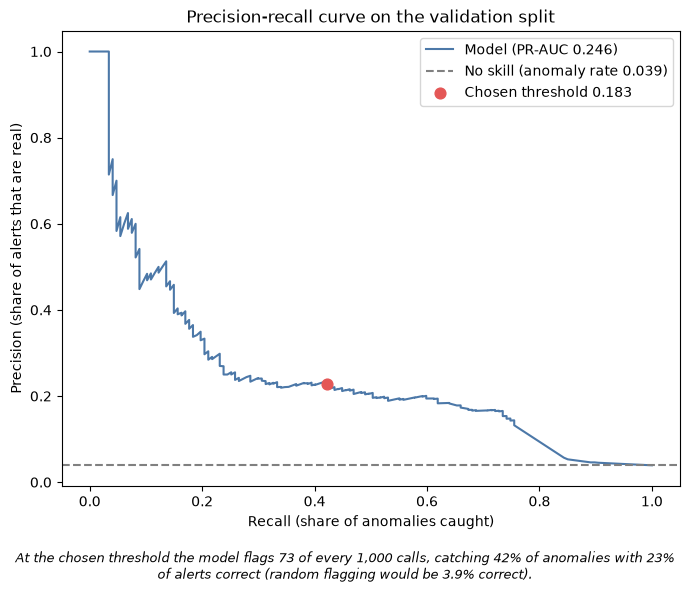

pr_curve_threshold.png: At the chosen threshold the model flags 73 of every 1,000 calls, catching 42% of anomalies with 23% of alerts correct (random flagging would be 3.9% correct).


In [9]:
prec_c, rec_c, _ = precision_recall_curve(y_val, val_platt)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(rec_c, prec_c, color="#4C78A8", label=f"Model (PR-AUC {average_precision_score(y_val, val_platt):.3f})")
ax.axhline(rate, color="gray", linestyle="--", label=f"No skill (anomaly rate {rate:.3f})")
ax.scatter([val_rec], [val_prec], color="#E45756", zorder=5, s=60, label=f"Chosen threshold {thr:.3f}")
ax.set_xlabel("Recall (share of anomalies caught)")
ax.set_ylabel("Precision (share of alerts that are real)")
ax.set_title("Precision-recall curve on the validation split")
ax.legend(loc="upper right")
fig.tight_layout()
finish(
    fig,
    "pr_curve_threshold.png",
    f"At the chosen threshold the model flags {1000 * flagged.mean():.0f} of every 1,000 calls, "
    f"catching {val_rec:.0%} of anomalies with {val_prec:.0%} of alerts correct "
    f"(random flagging would be {rate:.1%} correct).",
)

## 5. Save the calibrator and threshold
`models/threshold.json` holds what is needed to turn a raw model score into a calibrated probability and an alert decision.

In [10]:
payload = {
    "calibration": "Platt scaling on the log-odds of the raw score, fitted on out-of-fold training scores",
    "platt_coef": float(platt.coef_[0, 0]),
    "platt_intercept": float(platt.intercept_[0]),
    "threshold_calibrated": thr,
    "threshold_rule": rule,
    "validation": {
        "precision": round(float(val_prec), 4),
        "recall": round(float(val_rec), 4),
        "alerts_per_1000_calls": round(float(1000 * flagged.mean()), 1),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
    },
}
with open(ROOT / "models" / "threshold.json", "w", encoding="utf-8") as f:
    json.dump(payload, f, indent=2)
print(json.dumps(payload, indent=2))

{
  "calibration": "Platt scaling on the log-odds of the raw score, fitted on out-of-fold training scores",
  "platt_coef": 1.4748992396708474,
  "platt_intercept": -3.1170619036998977,
  "threshold_calibrated": 0.183416106926086,
  "threshold_rule": "maximum F1",
  "validation": {
    "precision": 0.2271,
    "recall": 0.4218,
    "alerts_per_1000_calls": 72.8,
    "tp": 62,
    "fp": 211,
    "fn": 85,
    "tn": 3392
  }
}


## Findings
Fill in after reading the outputs above:
- Are the raw scores probabilities? (compare the mean raw score with the true rate, and the Brier scores)
- Which calibrator is better on validation, and by how much?
- Chosen threshold, the rule used, and the precision and recall it gives on validation, with the intervals.
- What the alert volume means for a reviewer (alerts per 1,000 calls).
- Limitation: validation holds only about 150 anomalies, so single-split numbers are noisy.